# #204 Track A Gate B — retrospective anchored-method correction

This notebook audits the single PI-authorized `RETROSPECTIVE_METHOD_CORRECTION` package and runs a bounded synthetic fixture through the same reusable anchored-fit path. It does not refit or reopen the locked test or choose parameters. The former implementation-recovery package remains separate, immutable, and nonconforming product-ensemble diagnostic evidence.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
from IPython.display import Image, Markdown, display

package = Path('results/bj204_gate_b_retrospective_method_correction_v1')
assert package.is_dir(), package
manifest = json.loads((package / 'SHA256SUMS.json').read_text())
bad = [name for name, expected in manifest.items() if hashlib.sha256((package / name).read_bytes()).hexdigest() != expected]
assert not bad, bad
print(f'Package manifest PASS: {len(manifest)} payloads')

Package manifest PASS: 27 payloads


## Frozen contract and source binding

In [2]:
config = json.loads((package / 'model_config.json').read_text())
provenance = json.loads((package / 'provenance.json').read_text())
display(pd.DataFrame([{'version': config['version'], 'execution_status': config['execution_status'], 'composition': config['probability_composition'], 'gate_a_manifest': config['gate_a_manifest_sha256'], 'label_source_sha256': provenance['official_label_source_sha256']}]))
display(pd.DataFrame(config['models']).T)
display(pd.DataFrame([config['anchored_probability_method']]))
assert config['execution_status'] == 'RETROSPECTIVE_METHOD_CORRECTION'

,version,execution_status,composition,gate_a_manifest,label_source_sha256
0,bj204-market-anchored-model-gate-b-retrospecti...,RETROSPECTIVE_METHOD_CORRECTION,softmax(log(frozen_market_probability_3_1_0) +...,dfa14d42410d5513cbb07f832972e47fa1cf819a6f1eec...,e7256d96a34c2f41ede349c87b9cd1efc7a61b104657a6...


,learning_rate,max_iter,max_leaf_nodes,package,hidden_layer_sizes,representation,scope,torch_status,C,implementation
HIST_GRADIENT_RESIDUAL,0.05,60,8,sklearn,NaN,NaN,NaN,NaN,NaN,NaN
ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,NaN,50,NaN,sklearn,[32],permutation_invariant_issue_mean_std_max_min,issue-summary MLP control; not a learned-pooli...,not installed in frozen repository environment...,NaN,NaN
LOGISTIC_RESIDUAL,NaN,300,NaN,sklearn,NaN,NaN,NaN,NaN,0.5,NaN
SP_HEAD,NaN,60,NaN,sklearn,NaN,NaN,NaN,NaN,NaN,three HistGradientBoostingRegressor heads


,direction_model_package,offset_optimizer_package,optimizer_maxiter,optimizer_method,optimizer_xatol,residual_scale_bounds,selection_grid_changed,training_logits,version,zero_improvement_rule
0,scikit-learn,scipy.optimize.minimize_scalar,100,bounded,1.000000e-10,"[0.0, 1.0]",False,log(frozen_market_probability_3_1_0) + alpha *...,bj204-market-offset-residual-direction-scale-v1,alpha=0 when anchored training loss does not i...


## Corrected training objective — bounded production-path fixture

In [3]:
import sys
import numpy as np
from sklearn.linear_model import LogisticRegression
sys.path.insert(0, str(Path.cwd() / 'src'))
from unified_model.gate_b import AnchoredResidualEstimator, _anchored_probabilities, _metrics

rng = np.random.default_rng(204001)
fixture_target = np.tile(np.arange(3), 60)
fixture_features = np.column_stack([fixture_target + rng.normal(0, 0.35, len(fixture_target)), rng.normal(size=len(fixture_target))])
fixture_market = np.tile(np.array([1/3, 1/3, 1/3]), (len(fixture_target), 1))
anchored = AnchoredResidualEstimator(LogisticRegression(C=0.5, max_iter=300, random_state=204001)).fit(fixture_features, fixture_target, fixture_market)
fixture_probabilities = _anchored_probabilities(fixture_market, anchored.predict_delta(fixture_features))
fixture = pd.DataFrame([{'training_logits': 'log(p_market) + alpha * centered_direction(x)', 'alpha': anchored.residual_scale, 'market_loss': anchored.baseline_loss, 'anchored_loss': anchored.anchored_loss, 'recomputed_loss': _metrics(fixture_probabilities, fixture_target)['log_loss']}])
assert anchored.optimizer_success and 0 <= anchored.residual_scale <= 1
assert abs(fixture.loc[0, 'anchored_loss'] - fixture.loc[0, 'recomputed_loss']) <= 1e-12
assert fixture.loc[0, 'anchored_loss'] < fixture.loc[0, 'market_loss']
display(fixture)

,training_logits,alpha,market_loss,anchored_loss,recomputed_loss
0,log(p_market) + alpha * centered_direction(x),1.0,1.098612,0.335095,0.335095


## Development-only selection and locked-test scores

In [4]:
selection = pd.read_csv(package / 'model_selection.csv')
metrics = pd.read_csv(package / 'metrics.csv')
display(selection)
locked = metrics[(metrics['split'] == 'LOCKED_TEST') & metrics['view'].isin(['PURE_MARKET', 'MODEL_ONLY_COVERED', 'FALLBACK_MIXED'])]
locked_summary = locked.groupby(['model_id', 'view'], as_index=False)[['log_loss','brier','ece_equal_mass','top1','top2','sp_mae','model_used_rows','fallback_rows','ood_rows','mean_delta_logit_l1']].mean()
display(locked_summary)
context_safe = locked_summary[(locked_summary['model_id'] == 'ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL') & (locked_summary['view'] == 'FALLBACK_MIXED')]
assert len(context_safe) == 1 and context_safe.iloc[0]['model_used_rows'] == 0 and context_safe.iloc[0]['fallback_rows'] == context_safe.iloc[0]['ood_rows'] == 16968
display(Markdown('**Context-arm disclosure:** all 16,968 market-eligible locked-test rows are OOD fallback for every frozen seed; model-used coverage is 0%. Its raw model-only score is diagnostic and its safe-mixed path supplies no learned-model evidence.'))

,model_id,mean_cv_log_loss,cv_rows,complexity_rank,selected_for_primary
0,LOGISTIC_RESIDUAL,1.147751,152394,1,True
1,HIST_GRADIENT_RESIDUAL,1.148999,152394,2,False
2,MARKET_ONLY,1.150530,152394,0,False
3,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,1.152227,152394,3,False


,model_id,view,log_loss,brier,ece_equal_mass,top1,top2,sp_mae,model_used_rows,fallback_rows,ood_rows,mean_delta_logit_l1
0,HIST_GRADIENT_RESIDUAL,FALLBACK_MIXED,1.142760,0.695702,0.127745,0.402345,0.717400,0.34515,16968.0,0.0,0.0,0.322149
1,HIST_GRADIENT_RESIDUAL,MODEL_ONLY_COVERED,1.142760,0.695702,0.127745,0.402345,0.717400,0.34515,16968.0,0.0,0.0,0.322149
2,HIST_GRADIENT_RESIDUAL,PURE_MARKET,1.147860,0.696426,0.099572,0.399513,0.687697,0.34515,0.0,0.0,0.0,0.322149
3,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,FALLBACK_MIXED,1.147860,0.696426,0.099572,0.399513,0.687697,0.34515,0.0,16968.0,16968.0,0.598036
4,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,MODEL_ONLY_COVERED,1.138335,0.693569,0.135349,0.405889,0.728509,0.34515,16968.0,0.0,16968.0,0.598036
5,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,PURE_MARKET,1.147860,0.696426,0.099572,0.399513,0.687697,0.34515,0.0,0.0,0.0,0.598036
6,LOGISTIC_RESIDUAL,FALLBACK_MIXED,1.143112,0.696018,0.123924,0.401770,0.707955,0.34515,16968.0,0.0,0.0,0.268521
7,LOGISTIC_RESIDUAL,MODEL_ONLY_COVERED,1.143112,0.696018,0.123924,0.401770,0.707955,0.34515,16968.0,0.0,0.0,0.268521
8,LOGISTIC_RESIDUAL,PURE_MARKET,1.147860,0.696426,0.099572,0.399513,0.687697,0.34515,0.0,0.0,0.0,0.268521
9,MARKET_ONLY,FALLBACK_MIXED,1.147860,0.696426,0.099572,0.399513,0.687697,0.34515,0.0,0.0,0.0,0.000000


**Context-arm disclosure:** all 16,968 market-eligible locked-test rows are OOD fallback for every frozen seed; model-used coverage is 0%. Its raw model-only score is diagnostic and its safe-mixed path supplies no learned-model evidence.

## Exact matched-baseline differences, calibration and coverage

,model_id,lift_log_loss,lift_brier,lift_ece_equal_mass,lift_top1,lift_top2,lift_sp_mae
0,HIST_GRADIENT_RESIDUAL,-0.005100,-0.000724,0.028173,0.002832,0.029704,0.0
1,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,-0.009524,-0.002857,0.035777,0.006376,0.040813,0.0
2,LOGISTIC_RESIDUAL,-0.004748,-0.000409,0.024352,0.002257,0.020258,0.0


,split,model_id,seed,anchored_method_version,residual_scale_alpha,anchored_train_market_log_loss,anchored_train_fitted_log_loss,anchored_train_improvement,anchored_optimizer_success
0,CV_2021,HIST_GRADIENT_RESIDUAL,204001,bj204-market-offset-residual-direction-scale-v1,0.759068,1.166114,1.150777,0.015337,True
1,CV_2021,HIST_GRADIENT_RESIDUAL,204002,bj204-market-offset-residual-direction-scale-v1,0.745999,1.166114,1.151499,0.014615,True
2,CV_2021,HIST_GRADIENT_RESIDUAL,204003,bj204-market-offset-residual-direction-scale-v1,0.752053,1.166114,1.151126,0.014988,True
3,CV_2021,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,204001,bj204-market-offset-residual-direction-scale-v1,0.751742,1.166114,1.145087,0.021027,True
4,CV_2021,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,204002,bj204-market-offset-residual-direction-scale-v1,0.624552,1.166114,1.151830,0.014284,True
5,CV_2021,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,204003,bj204-market-offset-residual-direction-scale-v1,0.685852,1.166114,1.147928,0.018186,True
6,CV_2021,LOGISTIC_RESIDUAL,204001,bj204-market-offset-residual-direction-scale-v1,0.569280,1.166114,1.156630,0.009483,True
7,CV_2021,LOGISTIC_RESIDUAL,204002,bj204-market-offset-residual-direction-scale-v1,0.569280,1.166114,1.156630,0.009483,True
8,CV_2021,LOGISTIC_RESIDUAL,204003,bj204-market-offset-residual-direction-scale-v1,0.569280,1.166114,1.156630,0.009483,True
9,CV_2021,MARKET_ONLY,204001,bj204-market-offset-residual-direction-scale-v1,0.000000,NaN,NaN,NaN,False


,split,model_id,seed,eligible_rows,model_used_rows,fallback_rows,ood_rows
0,CV_2021,HIST_GRADIENT_RESIDUAL,204001,18624,18624,0,0
1,CV_2021,HIST_GRADIENT_RESIDUAL,204002,18624,18624,0,0
2,CV_2021,HIST_GRADIENT_RESIDUAL,204003,18624,18624,0,0
3,CV_2021,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,204001,18624,18594,30,30
4,CV_2021,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,204002,18624,18594,30,30
5,CV_2021,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,204003,18624,18594,30,30
6,CV_2021,LOGISTIC_RESIDUAL,204001,18624,18624,0,0
7,CV_2021,LOGISTIC_RESIDUAL,204002,18624,18624,0,0
8,CV_2021,LOGISTIC_RESIDUAL,204003,18624,18624,0,0
9,CV_2021,MARKET_ONLY,204001,18624,0,0,0


,split,model_id,seed,outcome_code,target_rows,prediction_rows,matched_rows,mae,mean_actual_sp,mean_predicted_sp
0,CV_2021,HIST_GRADIENT_RESIDUAL,204001,0,18626,18881,18626,0.433294,3.165637,3.160949
1,CV_2021,HIST_GRADIENT_RESIDUAL,204001,1,18626,18881,18626,0.327601,3.691630,3.726624
2,CV_2021,HIST_GRADIENT_RESIDUAL,204001,3,18626,18881,18626,0.379162,2.901500,2.886510
3,CV_2021,HIST_GRADIENT_RESIDUAL,204002,0,18626,18881,18626,0.433309,3.165637,3.162307
4,CV_2021,HIST_GRADIENT_RESIDUAL,204002,1,18626,18881,18626,0.327395,3.691630,3.725190
...,...,...,...,...,...,...,...,...,...,...
139,LOCKED_TEST,MARKET_ONLY,204002,1,16851,16990,16851,0.321967,3.779747,3.770587
140,LOCKED_TEST,MARKET_ONLY,204002,3,16851,16990,16851,0.328918,2.837604,2.817376
141,LOCKED_TEST,MARKET_ONLY,204003,0,16851,16990,16851,0.383544,3.107558,3.151033
142,LOCKED_TEST,MARKET_ONLY,204003,1,16851,16990,16851,0.322054,3.779747,3.769267


,bin,rows,mean_confidence,accuracy
0,1,1684,0.376289,0.347981
1,2,1684,0.409668,0.389549
2,3,1684,0.438302,0.403800
3,4,1683,0.464531,0.396910
4,5,1683,0.492383,0.421866
5,6,1683,0.523033,0.400475
6,7,1683,0.555073,0.417112
7,8,1683,0.593861,0.425431
8,9,1683,0.649903,0.395722
9,10,1683,0.754108,0.418895


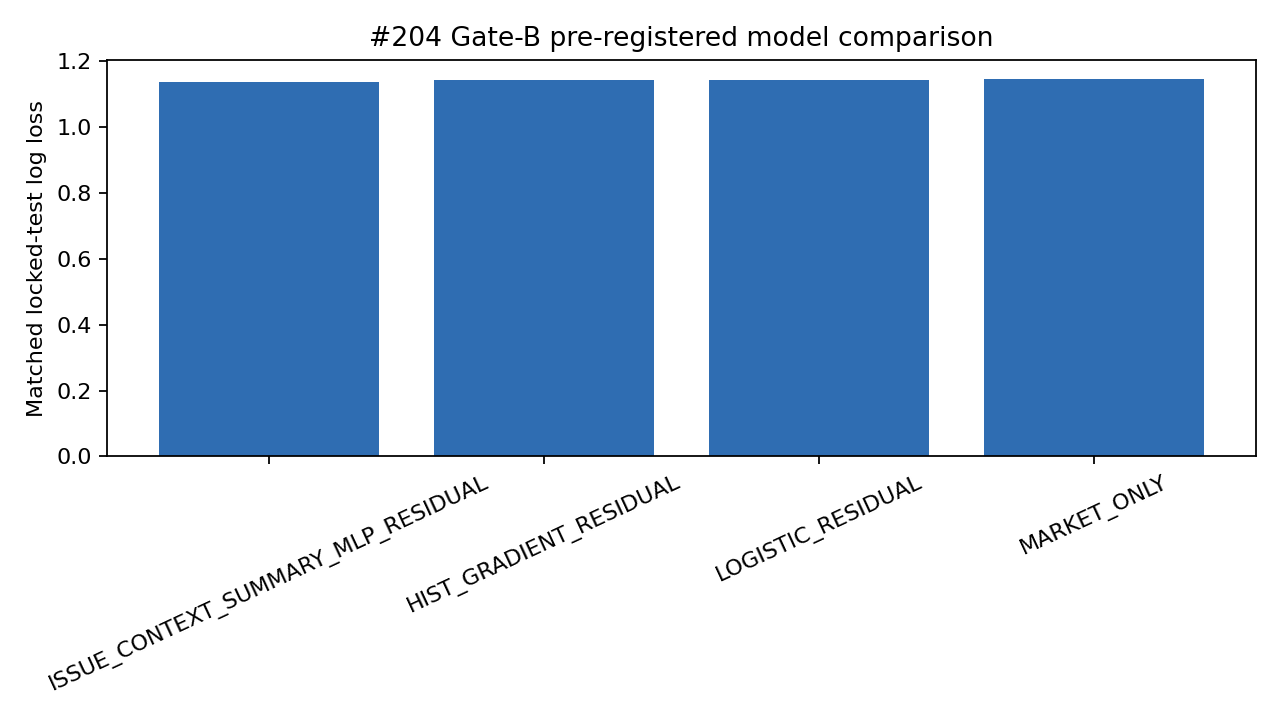

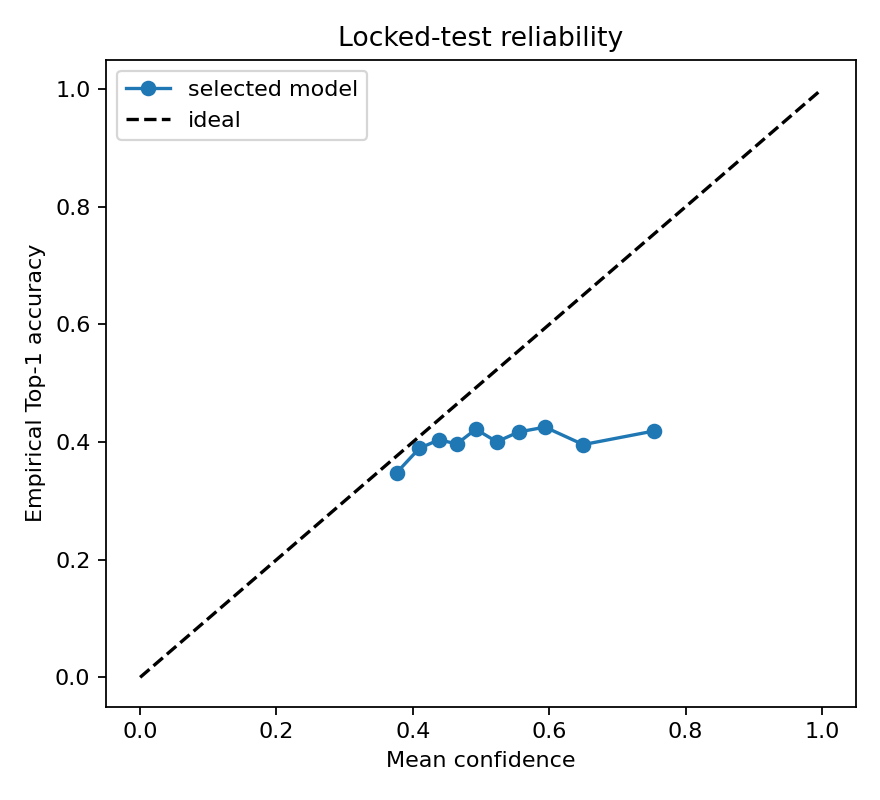

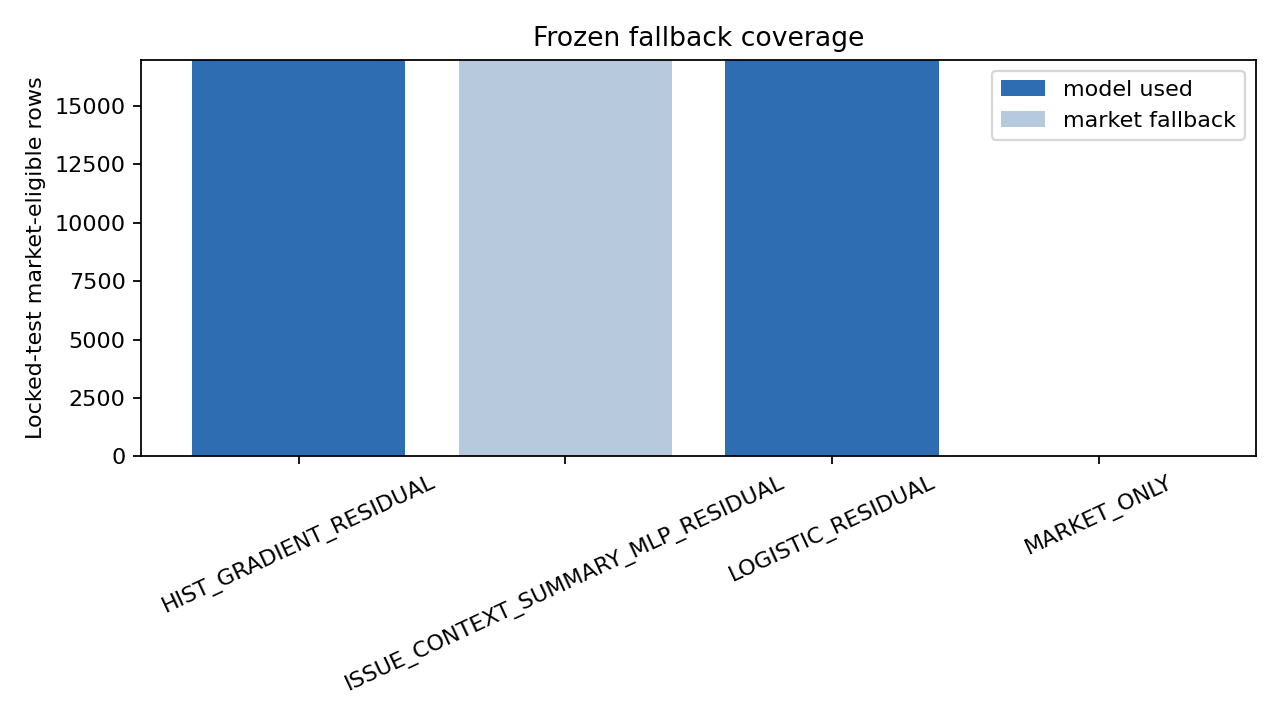

In [5]:
deltas = pd.read_csv(package / 'matched_baseline_deltas.csv')
display(deltas[deltas['split'] == 'LOCKED_TEST'].groupby('model_id', as_index=False)[['lift_log_loss','lift_brier','lift_ece_equal_mass','lift_top1','lift_top2','lift_sp_mae']].mean())
display(pd.read_csv(package / 'fitted_alpha.csv'))
display(pd.read_csv(package / 'fallback_ood_coverage.csv'))
display(pd.read_csv(package / 'sp_head_diagnostics.csv'))
display(pd.read_csv(package / 'locked_test_calibration.csv'))
for filename in ('locked_test_log_loss.png', 'locked_test_calibration.png', 'locked_test_coverage.png'):
    display(Image(filename=str(package / filename)))

## Decision

In [6]:
display(Markdown((package / 'DECISION_REPORT.md').read_text()))

# #204 Gate B — bounded market-residual model decision

## Scope

This is the single PI-authorized RETROSPECTIVE_METHOD_CORRECTION. It tests a conservative one-direction-plus-scalar anchored residual control, not a fully joint learned residual encoder and not every possible neural residual hypothesis. It is proxy-grade research only and grants no betting, ROI, ticket, production, #205, or #210 authority.

## Frozen selection

The development-only expanding-CV rule selected `LOGISTIC_RESIDUAL`. No locked-test metric selected a model or hyperparameter.

## Locked 75-issue result

- Matched market-label rows: 16833.
- Model-only log loss: 1.143112; market: 1.147860; lift: -0.004748.
- Model-only Brier: 0.696018; market: 0.696426.
- Model-only ECE: 0.123924; market: 0.099572.
- Model-only Top1/Top2: 0.401770 / 0.707955; market: 0.399513 / 0.687697.

## Residual ablation versus the matched market baseline

Negative log-loss/Brier/ECE lift is better. These one-shot retrospective values cannot authorize promotion without #210.
| Residual family | log-loss lift vs market | Brier lift | ECE lift | mean delta-logit L1 |
|---|---:|---:|---:|---:|
| HIST_GRADIENT_RESIDUAL | -0.005100 | -0.000724 | +0.028173 | 0.322149 |
| ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL | -0.009524 | -0.002857 | +0.035777 | 0.598036 |
| LOGISTIC_RESIDUAL | -0.004748 | -0.000409 | +0.024352 | 0.268521 |

## Fitted anchored scale

Alpha is fitted on the corresponding training window only with the frozen market offset inside the loss.
| Residual family | Seed | fitted alpha | market train log loss | anchored train log loss |
|---|---:|---:|---:|---:|
| HIST_GRADIENT_RESIDUAL | 204001 | 0.53595290 | 1.15661516 | 1.14918532 |
| HIST_GRADIENT_RESIDUAL | 204002 | 0.53279076 | 1.15661516 | 1.14931209 |
| HIST_GRADIENT_RESIDUAL | 204003 | 0.54394923 | 1.15661516 | 1.14908592 |
| ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL | 204001 | 0.53348926 | 1.15661516 | 1.14677212 |
| ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL | 204002 | 0.57464683 | 1.15661516 | 1.14576287 |
| ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL | 204003 | 0.60800551 | 1.15661516 | 1.14550265 |
| LOGISTIC_RESIDUAL | 204001 | 0.44515601 | 1.15661516 | 1.15108044 |
| LOGISTIC_RESIDUAL | 204002 | 0.44515601 | 1.15661516 | 1.15108044 |
| LOGISTIC_RESIDUAL | 204003 | 0.44515601 | 1.15661516 | 1.15108044 |

## Safe fallback interpretation

The frozen OOD rule marked 0 of 16968 market-eligible locked-test rows as OOD; model output was used on 16968 and exact market fallback on 0. The fallback-mixed log loss is 1.143112.
The issue-context summary MLP used learned output on 0 of 16968 market-eligible locked-test rows; 16968 fell back and 16968 were OOD. When model-used coverage is zero, its raw MODEL_ONLY_COVERED score is diagnostic only and its safe-mixed path supplies no learned-model evidence.
Expected missing predicted-SP inputs are median-imputed with indicators and do not become synthetic OOD. This retrospective method correction cannot promote a probability or SP model; #210 remains the sole strict confirmation.

## Decision

`RETROSPECTIVE_METHOD_CORRECTION_PENDING_PI_TERMINAL_REVIEW`: retain the frozen market/NO_BET fallback, do not retune or rerun, and submit this one-shot package to PI.
